# Brief Seattle — Analyse exploratoire

Chargement des relevés 2016 (*Building Energy Benchmarking*) de la ville de Seattle.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)  # afficher toutes les colonnes (46)

RANDOM_STATE = 42  # graine fixée pour la reproductibilité

## Chargement des données

In [2]:
# Chemin relatif au dossier notebooks/
DATA_PATH = Path("..") / "data" / "raw" / "2016_Building_Energy_Benchmarking.csv"

df = pd.read_csv(DATA_PATH)
print(f"{df.shape[0]} lignes x {df.shape[1]} colonnes")

3376 lignes x 46 colonnes


In [3]:
df.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   str    
 3   PrimaryPropertyType              3376 non-null   str    
 4   PropertyName                     3376 non-null   str    
 5   Address                          3376 non-null   str    
 6   City                             3376 non-null   str    
 7   State                            3376 non-null   str    
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   str    
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   str    
 12  Latitude                       

In [5]:
df.isna().sum()

OSEBuildingID                         0
DataYear                              0
BuildingType                          0
PrimaryPropertyType                   0
PropertyName                          0
Address                               0
City                                  0
State                                 0
ZipCode                              16
TaxParcelIdentificationNumber         0
CouncilDistrictCode                   0
Neighborhood                          0
Latitude                              0
Longitude                             0
YearBuilt                             0
NumberofBuildings                     8
NumberofFloors                        0
PropertyGFATotal                      0
PropertyGFAParking                    0
PropertyGFABuilding(s)                0
ListOfAllPropertyUseTypes             9
LargestPropertyUseType               20
LargestPropertyUseTypeGFA            20
SecondLargestPropertyUseType       1697
SecondLargestPropertyUseTypeGFA    1697


In [6]:
#compte des bâtiments par type d'usage

df["BuildingType"].value_counts()


BuildingType
NonResidential          1460
Multifamily LR (1-4)    1018
Multifamily MR (5-9)     580
Multifamily HR (10+)     110
SPS-District K-12         98
Nonresidential COS        85
Campus                    24
Nonresidential WA          1
Name: count, dtype: int64

In [7]:
# Le brief cible les bâtiments non destinés à l'habitation :
# on exclut les logements collectifs (Multifamily LR / MR / HR)
df = df[~df["BuildingType"].str.startswith("Multifamily")]
print(df.shape)


(1668, 46)


In [8]:
df["PrimaryPropertyType"].value_counts()

PrimaryPropertyType
Small- and Mid-Sized Office    292
Other                          250
Warehouse                      187
Large Office                   173
K-12 School                    139
Mixed Use Property             114
Retail Store                    91
Hotel                           76
Worship Facility                71
Distribution Center             53
Supermarket / Grocery Store     40
Medical Office                  39
Self-Storage Facility           28
University                      24
Residence Hall                  21
Senior Care Community           20
Refrigerated Warehouse          12
Restaurant                      12
Hospital                        10
Laboratory                      10
Low-Rise Multifamily             3
Office                           3
Name: count, dtype: int64

In [9]:
df = df[df["PrimaryPropertyType"] != "Low-Rise Multifamily"]


In [10]:
df["ComplianceStatus"].value_counts()

ComplianceStatus
Compliant                       1546
Error - Correct Default Data      88
Non-Compliant                     17
Missing Data                      14
Name: count, dtype: int64

In [11]:
df["Outlier"].value_counts(dropna=False)

Outlier
NaN             1649
Low outlier       14
High outlier       2
Name: count, dtype: int64

In [12]:
# On retire les relevés invalidés par la ville :
# - "Missing Data" : consommation à 0, pas de vrai relevé
# - "Non-Compliant" : données non validées (contient 16 des 18 outliers)
# - Outlier : valeurs signalées comme anormales par la ville
# On garde "Error - Correct Default Data" : consommations plausibles,
# l'erreur porte sur la déclaration, pas sur la mesure.
df = df[~df["ComplianceStatus"].isin(["Missing Data", "Non-Compliant"])]
df = df[df["Outlier"].isna()]
print(df.shape)

(1632, 46)


In [13]:
cibles = ["SiteEnergyUse(kBtu)", "TotalGHGEmissions"]
df[(df[cibles] <= 0).any(axis=1)][["PropertyName"] + cibles + ["Electricity(kBtu)", "NaturalGas(kBtu)"]]


,PropertyName,SiteEnergyUse(kBtu),TotalGHGEmissions,Electricity(kBtu),NaturalGas(kBtu)
513,IUC- Whole Foods Interbay,1.252517e+07,0.0,0.0,0.0
1361,Olympic Hills Elementary,0.000000e+00,0.0,0.0,0.0
3206,Bullitt Center,3.427261e+05,-0.8,-115417.0,0.0


In [14]:
# 3 lignes avec des cibles nulles ou négatives :
# - Olympic Hills Elementary : relevé vide (tout à 0)
# - Whole Foods Interbay : énergie > 0 mais émissions/électricité/gaz à 0, incohérent
# - Bullitt Center : bâtiment à énergie positive (panneaux solaires), émissions
#   négatives réelles mais cas isolé et non modélisable
df = df[(df[cibles] > 0).all(axis=1)]
print(df.shape)  # 1629 lignes


(1629, 46)


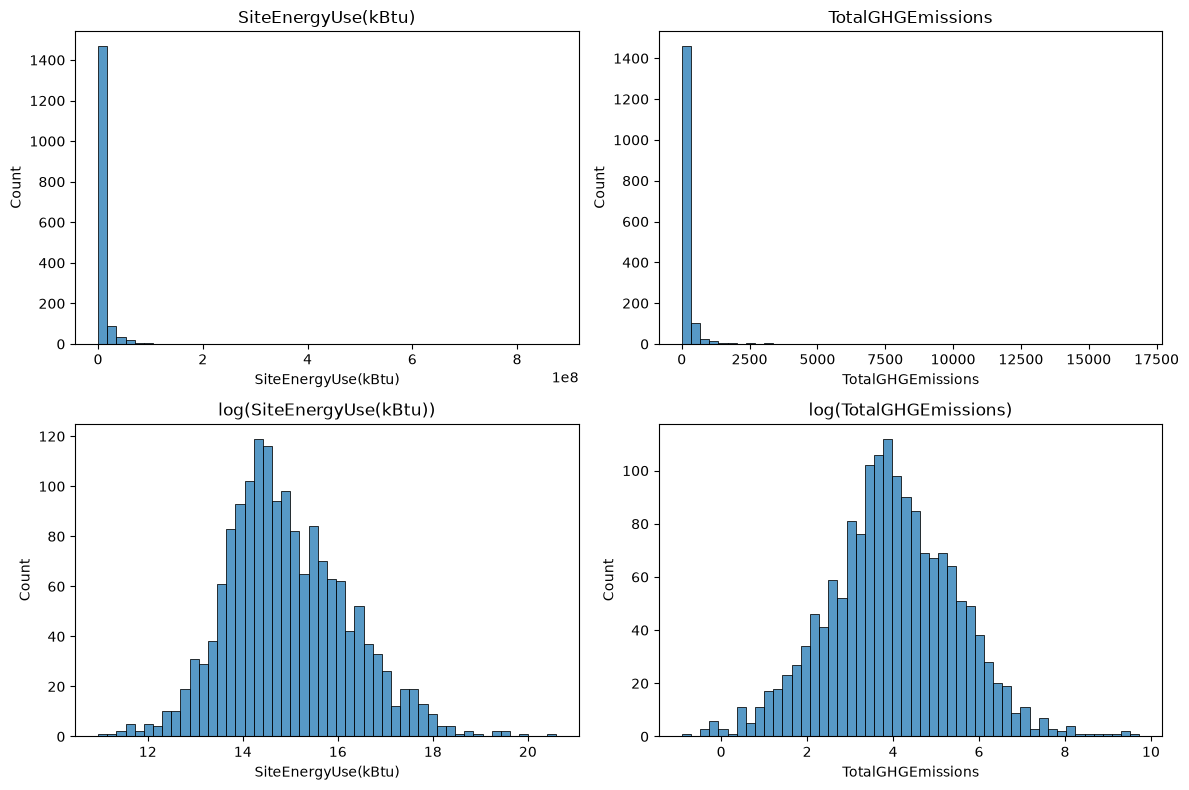

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, col in enumerate(cibles):
    sns.histplot(df[col], ax=axes[0, i], bins=50).set_title(col)
    sns.histplot(np.log(df[col]), ax=axes[1, i], bins=50).set_title(f"log({col})")
plt.tight_layout()


In [16]:
na = df.isna().sum()
na = na[na > 0].sort_values(ascending=False)
pd.DataFrame({"nb": na, "%": (na / len(df) * 100).round(1)})



,nb,%
Comments,1629,100.0
Outlier,1629,100.0
YearsENERGYSTARCertified,1532,94.0
ThirdLargestPropertyUseType,1280,78.6
ThirdLargestPropertyUseTypeGFA,1280,78.6
SecondLargestPropertyUseTypeGFA,784,48.1
SecondLargestPropertyUseType,784,48.1
ENERGYSTARScore,550,33.8
ZipCode,16,1.0
LargestPropertyUseType,4,0.2


In [17]:
(df["SecondLargestPropertyUseType"].isna() == df["SecondLargestPropertyUseTypeGFA"].isna()).all()  # True



np.True_

In [18]:
# Absence de 2e/3e usage = le bâtiment n'en a pas → on remplit explicitement
for rang in ["Second", "Third"]:
    df[f"{rang}LargestPropertyUseType"] = df[f"{rang}LargestPropertyUseType"].fillna("None")
    df[f"{rang}LargestPropertyUseTypeGFA"] = df[f"{rang}LargestPropertyUseTypeGFA"].fillna(0)

# 4 bâtiments sans usage principal : on reprend le type principal et la surface bâtie
df["LargestPropertyUseType"] = df["LargestPropertyUseType"].fillna(df["PrimaryPropertyType"])
df["LargestPropertyUseTypeGFA"] = df["LargestPropertyUseTypeGFA"].fillna(df["PropertyGFABuilding(s)"])


In [19]:
df.groupby(df["ENERGYSTARScore"].isna())["PrimaryPropertyType"].value_counts().unstack(0)


ENERGYSTARScore,False,True
PrimaryPropertyType,,
Distribution Center,40.0,13.0
Hospital,10.0,NaN
Hotel,72.0,3.0
K-12 School,122.0,1.0
Laboratory,NaN,10.0
Large Office,161.0,9.0
Medical Office,37.0,2.0
Mixed Use Property,26.0,87.0
Office,3.0,NaN


### Cas particulier : `ENERGYSTARScore` (34 % de valeurs manquantes)

Le tableau ci-dessus montre que les valeurs manquantes ne sont **pas réparties au hasard** : elles dépendent du type de bâtiment.
- Certains types n'ont **jamais** de score : `University`, `Restaurant`, `Laboratory`, `Self-Storage Facility`.
- D'autres en ont presque toujours : `Small- and Mid-Sized Office`, `Warehouse`, `Retail Store`.

L'ENERGY STAR Score n'est en effet calculable que pour certaines catégories de bâtiments. Une valeur manquante signifie donc le plus souvent que le bâtiment **n'est pas éligible**, et non que la mesure a été oubliée.

**Conséquence : on n'impute pas cette colonne.** La remplacer par la médiane ou la moyenne inventerait un score pour des bâtiments qui ne peuvent pas en avoir, et fausserait l'évaluation de son intérêt.

**Décision :** on conserve la colonne telle quelle (avec ses NaN) pour la phase de modélisation, où l'on comparera :
- **Modèle A, sans le score**, entraîné sur l'ensemble des bâtiments ;
- **Modèle B, avec le score**, entraîné sur les bâtiments qui en disposent.

Pour que la comparaison soit équitable, les deux modèles seront évalués **sur le même sous-ensemble de bâtiments** (ceux qui ont un score). L'écart de performance mesurera l'apport réel de l'ENERGY STAR Score à la prédiction des émissions de CO2.

In [20]:
cols_physiques = ["PropertyGFATotal", "PropertyGFAParking", "PropertyGFABuilding(s)",
                  "NumberofBuildings", "NumberofFloors", "YearBuilt"]
df[cols_physiques].describe()


,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),NumberofBuildings,NumberofFloors,YearBuilt
count,1.629000e+03,1629.000000,1.629000e+03,1629.000000,1629.000000,1629.000000
mean,1.193451e+05,13142.612646,1.062025e+05,1.170043,4.158993,1961.994475
std,2.990367e+05,42722.769523,2.856594e+05,2.962905,6.632500,32.685578
min,1.128500e+04,0.000000,3.636000e+03,0.000000,0.000000,1900.000000
25%,2.939400e+04,0.000000,2.836800e+04,1.000000,1.000000,1930.000000
50%,4.924300e+04,0.000000,4.721500e+04,1.000000,2.000000,1966.000000
75%,1.060410e+05,0.000000,9.542600e+04,1.000000,4.000000,1989.000000
max,9.320156e+06,512608.000000,9.320156e+06,111.000000,99.000000,2015.000000


In [21]:
# Campus UW : 111 bâtiments agrégés en une ligne, 19x plus grand que le 2e
# → pas un bâtiment individuel, valeur extrême isolée
df = df[df["PropertyName"] != "University of Washington - Seattle Campus"]


In [22]:
ecart = df["PropertyGFATotal"] - df["PropertyGFAParking"] - df["PropertyGFABuilding(s)"]
(ecart.abs() > 1).sum()  # 0


np.int64(0)

In [23]:
# 52 propriétés avec 0 bâtiment alors qu'elles ont une surface bâtie → erreur de saisie
df.loc[df["NumberofBuildings"] == 0, "NumberofBuildings"] = 1


In [24]:
df[df["NumberofFloors"] == 0][["PropertyName", "PrimaryPropertyType"]]

,PropertyName,PrimaryPropertyType
166,Grand Hyatt Seattle,Hotel
487,Arnold Pavilion,Medical Office
488,2200 Westlake - SEDO,Mixed Use Property
564,Pacific Place,Other
1754,HART First Hill LLC,Medical Office
1993,(ID#24086)Campus1:KC Metro Transit Atlantic Ce...,Other
3130,Sandpoint #5,Warehouse
3131,Sandpoint #25,Medical Office
3132,Sandpoint #29,Small- and Mid-Sized Office
3168,Magnuson,Other


In [25]:
df.nlargest(5, "NumberofFloors")[["PropertyName", "PrimaryPropertyType", "NumberofFloors"]]


,PropertyName,PrimaryPropertyType,NumberofFloors
1359,Seattle Chinese Baptist Church,Worship Facility,99
559,Columbia Center - 2015,Large Office,76
233,Seattle Municipal Tower (2030),Large Office,63
292,Two Union Square,Large Office,56
271,1201 Third Avenue,Large Office,55


In [26]:
# 0 étage (16 bâtiments) et 99 étages pour une église → valeurs impossibles,
# remplacées par la médiane du même PrimaryPropertyType
etages_impossibles = (df["NumberofFloors"] == 0) | (df["NumberofFloors"] == 99)
df.loc[etages_impossibles, "NumberofFloors"] = np.nan
df["NumberofFloors"] = df["NumberofFloors"].fillna(
    df.groupby("PrimaryPropertyType")["NumberofFloors"].transform("median")
)


In [27]:
print(df.nunique().sort_values().to_string())   # force l'affichage de toutes les lignes
       # trié : les colonnes à 0-1 valeur en haut



Comments                              0
Outlier                               0
DataYear                              1
State                                 1
City                                  1
ComplianceStatus                      2
DefaultData                           2
BuildingType                          5
CouncilDistrictCode                   7
NumberofBuildings                    14
Neighborhood                         19
PrimaryPropertyType                  21
ThirdLargestPropertyUseType          40
NumberofFloors                       43
ZipCode                              48
SecondLargestPropertyUseType         48
LargestPropertyUseType               56
YearsENERGYSTARCertified             64
ENERGYSTARScore                     100
YearBuilt                           113
SteamUse(kBtu)                      114
ThirdLargestPropertyUseTypeGFA      299
PropertyGFAParking                  324
ListOfAllPropertyUseTypes           367
GHGEmissionsIntensity               460


In [28]:
somme = df["Electricity(kBtu)"] + df["NaturalGas(kBtu)"] + df["SteamUse(kBtu)"]
(somme / df["SiteEnergyUse(kBtu)"]).describe()   # ≈ 1 partout


count    1628.000000
mean        0.997935
std         0.034021
min         0.209771
25%         1.000000
50%         1.000000
75%         1.000000
max         1.237346
dtype: float64

In [29]:
# 2 bâtiments dont électricité + gaz + vapeur dépasse la consommation totale
# (ratio > 1) : physiquement impossible → relevé incohérent, on les retire
somme = df["Electricity(kBtu)"] + df["NaturalGas(kBtu)"] + df["SteamUse(kBtu)"]
ratio = somme / df["SiteEnergyUse(kBtu)"]

print(df.loc[ratio > 1.05, "PropertyName"])  # affiche les 2 bâtiments concernés
df = df[ratio <= 1.05]
print(df.shape)  # 1626 lignes


563     Market Place I & II-2003 Western Avenue
2441                         Buttnick City Loan
Name: PropertyName, dtype: str
(1626, 46)


In [30]:
# Info de raccordement (connue sans relevé) : le bâtiment utilise-t-il du gaz / de la vapeur ?
df["UsesNaturalGas"] = (df["NaturalGas(kBtu)"] > 0).astype(int)
df["UsesSteam"] = (df["SteamUse(kBtu)"] > 0).astype(int)


In [31]:
# Plant 2 Site : campus déclaré comme bureaux (3 étages), mais 1er consommateur et
# 1er émetteur du jeu de données, avec une intensité 14x supérieure à la médiane de
# son type (consommation de gaz typique d'une activité industrielle).
# Activité non décrite par nos variables → non prédictible, retiré.
df = df[df["PropertyName"] != "Plant 2 Site"]

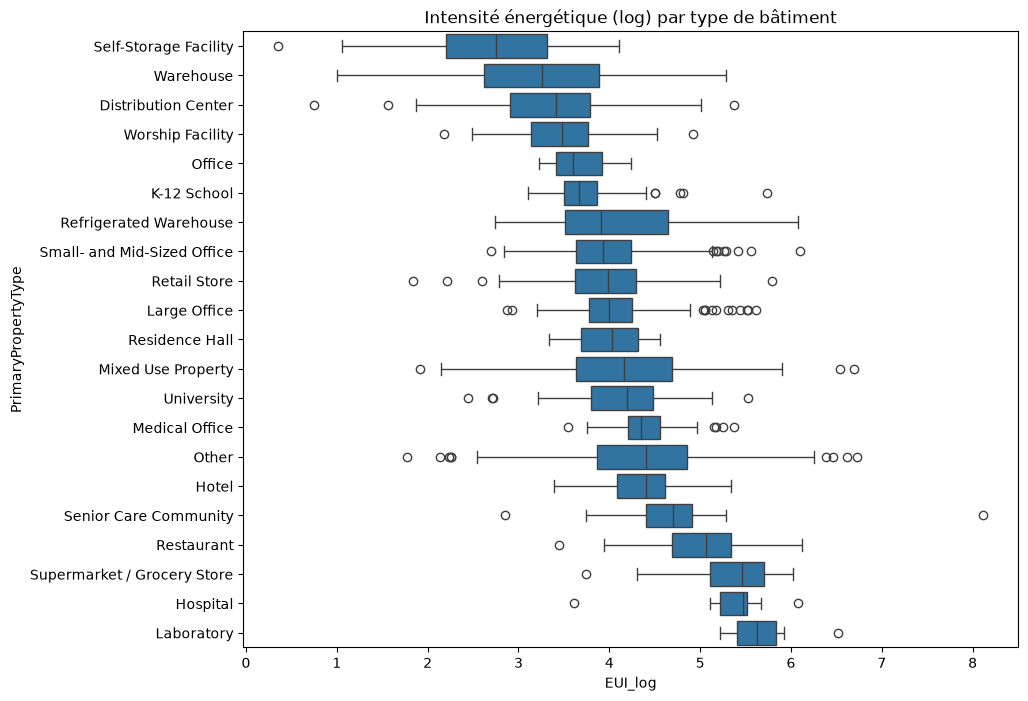

In [32]:
# Intensité énergétique (kBtu / pied²) : neutralise l'effet taille.
# Colonne temporaire pour l'analyse des outliers uniquement, à ne PAS garder comme variable
# (elle est calculée à partir de la cible → fuite de données)
df["EUI_log"] = np.log(df["SiteEnergyUse(kBtu)"] / df["PropertyGFABuilding(s)"])

ordre = df.groupby("PrimaryPropertyType")["EUI_log"].median().sort_values().index
plt.figure(figsize=(10, 8))
sns.boxplot(data=df, y="PrimaryPropertyType", x="EUI_log", order=ordre)
plt.title("Intensité énergétique (log) par type de bâtiment")
plt.show()


In [33]:
q1 = df.groupby("PrimaryPropertyType")["EUI_log"].transform(lambda x: x.quantile(0.25))
q3 = df.groupby("PrimaryPropertyType")["EUI_log"].transform(lambda x: x.quantile(0.75))
iqr = q3 - q1
extremes = (df["EUI_log"] < q1 - 3 * iqr) | (df["EUI_log"] > q3 + 3 * iqr)
df.loc[extremes, ["PropertyName", "PrimaryPropertyType", "EUI_log"]]


,PropertyName,PrimaryPropertyType,EUI_log
601,200 SW Michigan,Small- and Mid-Sized Office,6.099937
888,Cabrini Senior Housing,Senior Care Community,2.849180
954,University Prep Academy,K-12 School,5.740194
1109,Ballard Center,Senior Care Community,8.114095
2482,Park West Skilled Nursing,Hospital,3.614748


In [34]:
# Outliers extrêmes d'intensité énergétique (règle 3×IQR par type), examinés un par un :
# - Ballard Center, University Prep Academy : surface bâtie incohérente avec la surface
#   de l'usage principal (erreur de saisie) → retirés
# - Park West Skilled Nursing : classé Hospital (maison de soins), surface d'usage = 2x
#   la surface totale → retiré
# - Cabrini Senior Housing, 200 SW Michigan : surfaces cohérentes, valeurs extrêmes
#   confirmées par l'ENERGY STAR Score (100 et 1) → bâtiments réels, conservés
a_retirer = ["Ballard Center", "University Prep Academy", "Park West Skilled Nursing"]
df = df[~df["PropertyName"].isin(a_retirer)]
df = df.drop(columns="EUI_log")
print(df.shape)


(1622, 48)


In [35]:
colonnes_a_supprimer = [
    # Constantes / vides / identifiants
    "DataYear", "City", "State", "Comments",
    "OSEBuildingID", "PropertyName", "Address", "TaxParcelIdentificationNumber",
    # Déjà exploitées
    "ComplianceStatus", "Outlier", "DefaultData", "YearsENERGYSTARCertified", "ZipCode",
    # Redondantes
    "ListOfAllPropertyUseTypes", "CouncilDistrictCode", "PropertyGFATotal",
    # Fuites de données (issues du relevé de consommation)
    "SiteEUI(kBtu/sf)", "SiteEUIWN(kBtu/sf)", "SourceEUI(kBtu/sf)", "SourceEUIWN(kBtu/sf)",
    "SiteEnergyUseWN(kBtu)", "SteamUse(kBtu)", "Electricity(kWh)", "Electricity(kBtu)",
    "NaturalGas(therms)", "NaturalGas(kBtu)", "GHGEmissionsIntensity",
]
df = df.drop(columns=colonnes_a_supprimer)
print(df.shape)
df.columns.tolist()


(1622, 21)


['BuildingType',
 'PrimaryPropertyType',
 'Neighborhood',
 'Latitude',
 'Longitude',
 'YearBuilt',
 'NumberofBuildings',
 'NumberofFloors',
 'PropertyGFAParking',
 'PropertyGFABuilding(s)',
 'LargestPropertyUseType',
 'LargestPropertyUseTypeGFA',
 'SecondLargestPropertyUseType',
 'SecondLargestPropertyUseTypeGFA',
 'ThirdLargestPropertyUseType',
 'ThirdLargestPropertyUseTypeGFA',
 'ENERGYSTARScore',
 'SiteEnergyUse(kBtu)',
 'TotalGHGEmissions',
 'UsesNaturalGas',
 'UsesSteam']

In [36]:
print(df.shape)
df.isna().sum()[df.isna().sum() > 0]   # seule ENERGYSTARScore doit apparaître


(1622, 21)


ENERGYSTARScore    549
dtype: int64

In [37]:
df.head()

,BuildingType,PrimaryPropertyType,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions,UsesNaturalGas,UsesSteam
0,NonResidential,Hotel,DOWNTOWN,47.61220,-122.33799,1927,1.0,12.0,0,88434,Hotel,88434.0,None,0.0,None,0.0,60.0,7226362.5,249.98,1,1
1,NonResidential,Hotel,DOWNTOWN,47.61317,-122.33393,1996,1.0,11.0,15064,88502,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.0,8387933.0,295.86,1,0
2,NonResidential,Hotel,DOWNTOWN,47.61393,-122.33810,1969,1.0,41.0,196718,759392,Hotel,756493.0,None,0.0,None,0.0,43.0,72587024.0,2089.28,1,1
3,NonResidential,Hotel,DOWNTOWN,47.61412,-122.33664,1926,1.0,10.0,0,61320,Hotel,61320.0,None,0.0,None,0.0,56.0,6794584.0,286.43,1,1
4,NonResidential,Hotel,DOWNTOWN,47.61375,-122.34047,1980,1.0,18.0,62000,113580,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,75.0,14172606.0,505.01,1,0
